# Sell the Review Before You Scale the App

## tl;dr

Assisted direct preserves the most cash in the starting scenario. At the same $99 price, self-service preserves more cash. The model therefore tests an offer, customer and price combination; it does not identify a causal channel effect.

Full manuscript: [article.md](article.md).

## Context & Methods

Six 30-day periods after an approved working app exists. $40,000 starting cash; $6,000 fixed cash outflow including founder draws; $12/store variable cost; 60 delivery and 40 commercial hours. Existing customer support is admitted before new starts. New starts are whole; retained stores are expected values.

### Key Assumptions

Commercial demand, prices, churn, work, acquisition cost, agency commission and one-period collections are authored assumptions. Current Shopify fee terms are sourced in [SOURCES.md](SOURCES.md). Taxes, refunds, nonpayment and pre-launch costs are excluded.

## Data

### 1. Load the complete operating inputs

Local calculations require no network or credentials.

In [1]:
from model import results
from figures import cash_capacity, cash_paths
from pitches.figures import strategy_price
from IPython.display import display, Markdown, Image
import matplotlib.pyplot as plt
data=results()
for key,record in data['base'].items():
    print(key, record['inputs'])

self_service {'name': 'Self-service', 'price': 99, 'demand': (8, 12, 16, 20, 20, 20), 'churn': 0.04, 'onboarding_hours': 1.5, 'support_hours': 0.75, 'cash_acquisition_cost': 150, 'agency_share': 0, 'platform_share': 0, 'delivery_overhead': (0, 0, 0, 0, 0, 0), 'sales_hours_per_new': 0, 'commercial_overhead': (6, 6, 6, 6, 6, 6)}
assisted_direct {'name': 'Assisted direct', 'price': 399, 'demand': (3, 4, 5, 5, 5, 5), 'churn': 0.02, 'onboarding_hours': 4, 'support_hours': 0.5, 'cash_acquisition_cost': 150, 'agency_share': 0, 'platform_share': 0, 'delivery_overhead': (0, 0, 0, 0, 0, 0), 'sales_hours_per_new': 3, 'commercial_overhead': (0, 0, 0, 0, 0, 0)}
agency_referral {'name': 'Agency referral', 'price': 399, 'demand': (0, 0, 8, 8, 8, 8), 'churn': 0.02, 'onboarding_hours': 3, 'support_hours': 0.75, 'cash_acquisition_cost': 50, 'agency_share': 0.25, 'platform_share': 0, 'delivery_overhead': (12, 12, 4, 4, 4, 4), 'sales_hours_per_new': 1, 'commercial_overhead': (24, 24, 6, 6, 6, 6)}


## Results

### 2. Compare the starting offers

| Motion | Contribution | Ending cash | Period 6 delivery |
| --- | ---: | ---: | ---: |
| Self-service | $9,008 | $6,927 | 59.44h |
| Assisted direct | $27,993 | $21,993 | 32.90h |
| Agency referral | $20,018 | $15,084 | 51.29h |

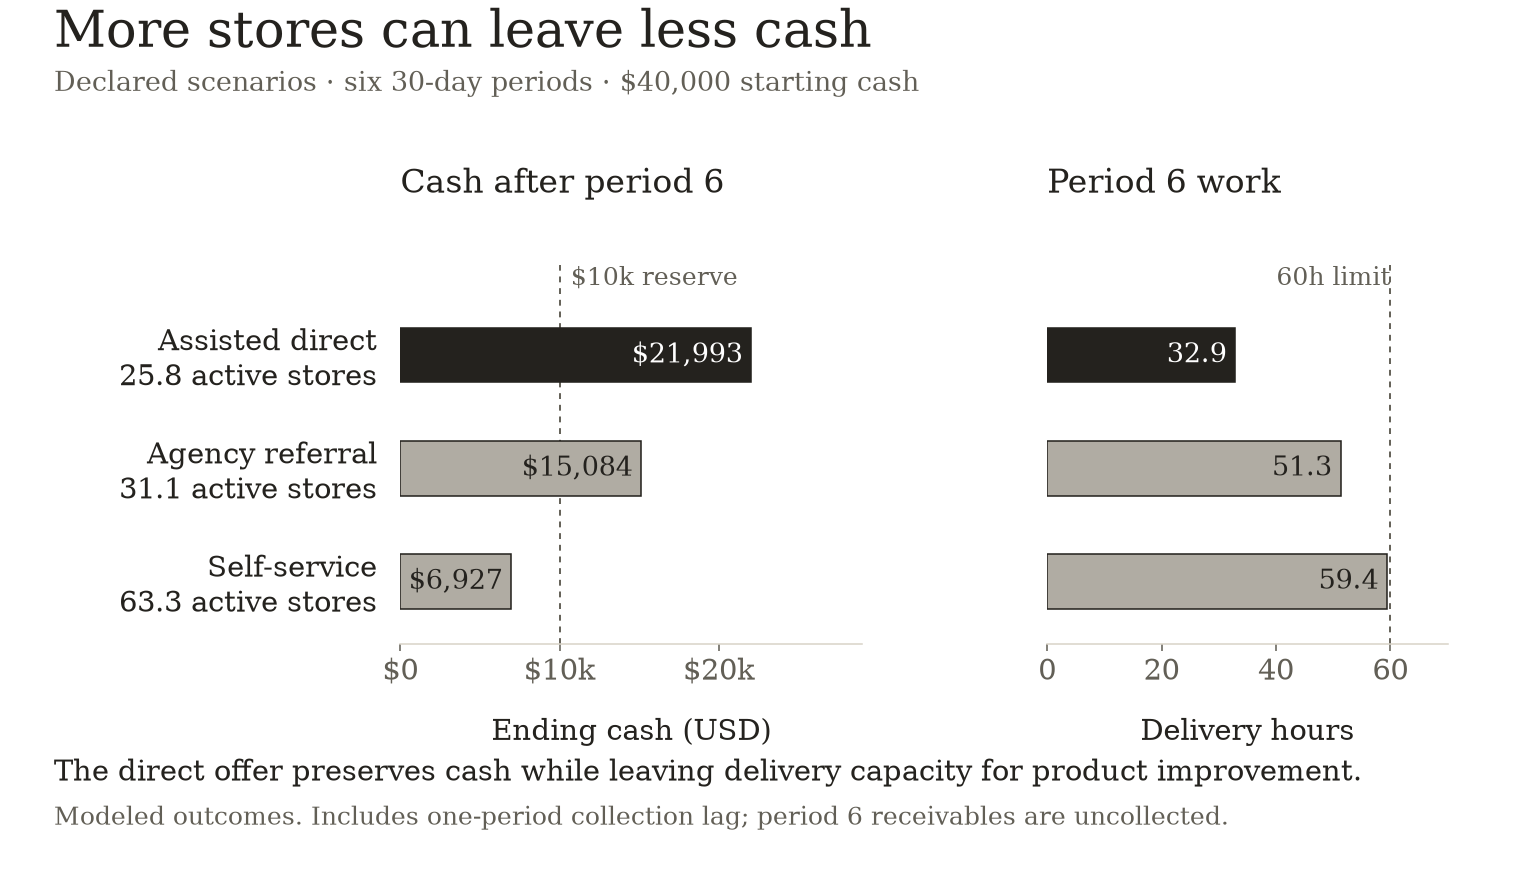

In [2]:
rows=['| Motion | Contribution | Ending cash | Period 6 delivery |','| --- | ---: | ---: | ---: |']
for r in data['base'].values():
    rows.append(f"| {r['inputs']['name']} | ${r['summary']['contribution']:,.0f} | ${r['summary']['final_cash']:,.0f} | {r['rows'][-1]['delivery_hours']:.2f}h |")
display(Markdown('\n'.join(rows)))
fig=cash_capacity(data)
display(Image(filename='figures/strategy-growth-channel-cash-capacity.png'))
plt.close(fig)

### 3. Hold price constant

These diagnostic counterfactuals hold each motion's demand and work fixed. They are not evidence of demand at the untested price.

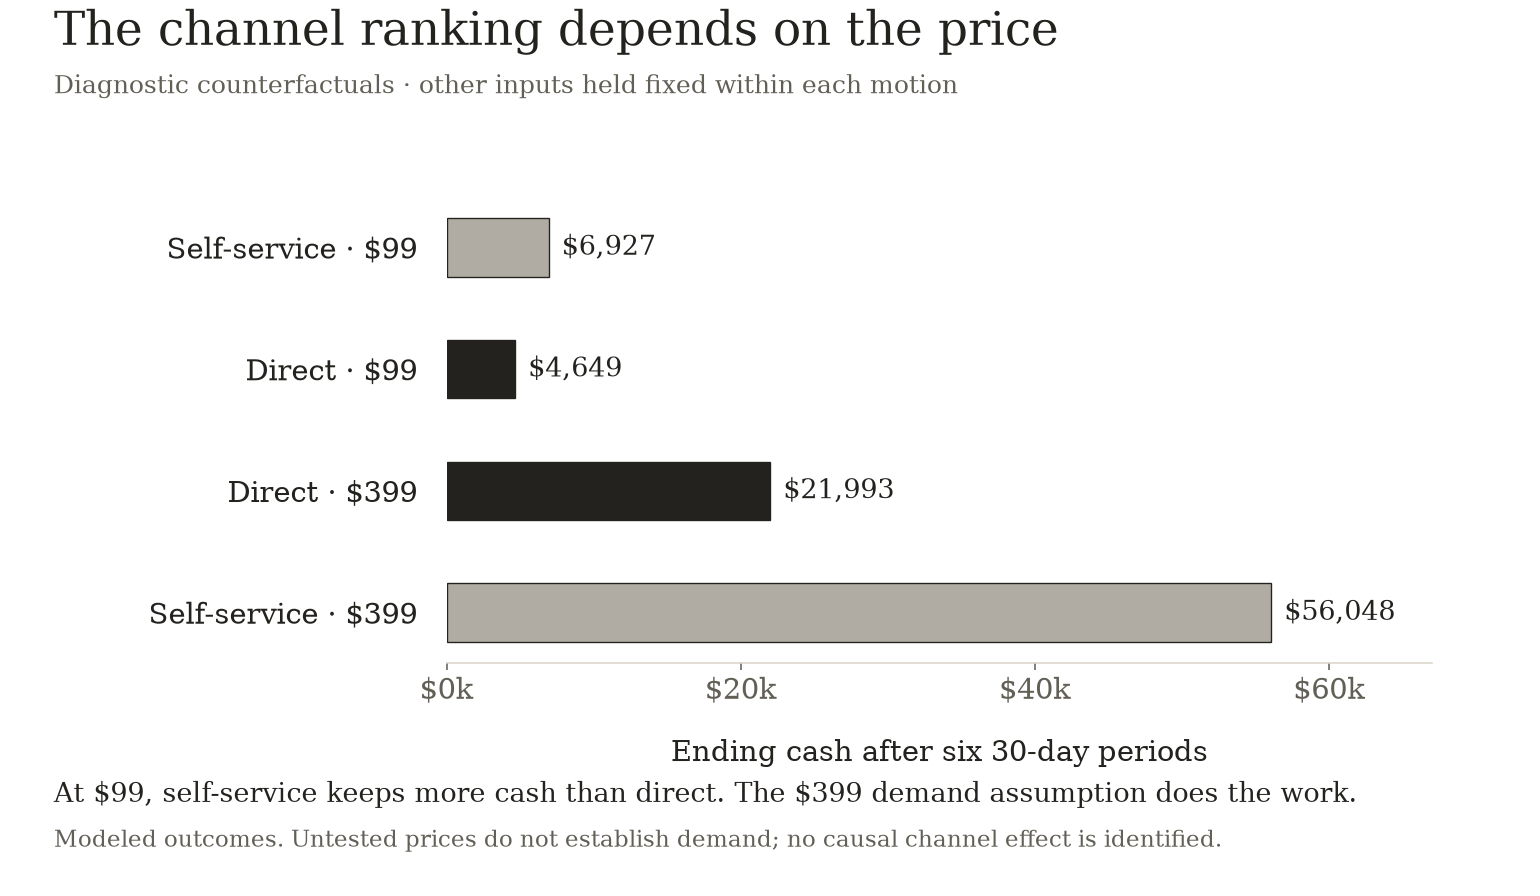

direct_at_self_service_price ending cash 4649.35 period 6 funding surplus -4578.7
self_service_at_direct_price ending cash 56048.44 period 6 funding surplus 16547.73
direct_three_starts ending cash 17545.01 period 6 funding surplus -21.29


In [3]:
fig=strategy_price(data)
display(Image(filename='figures/strategy-growth-price-counterfactual.png'))
plt.close(fig)
for key in ['direct_at_self_service_price','self_service_at_direct_price','direct_three_starts']:
    r=data['variants'][key]
    print(key, 'ending cash',round(r['summary']['final_cash'],2),'period 6 funding surplus',round(r['rows'][-1]['operating_result'],2))

### 4. Separate capacity and cash timing

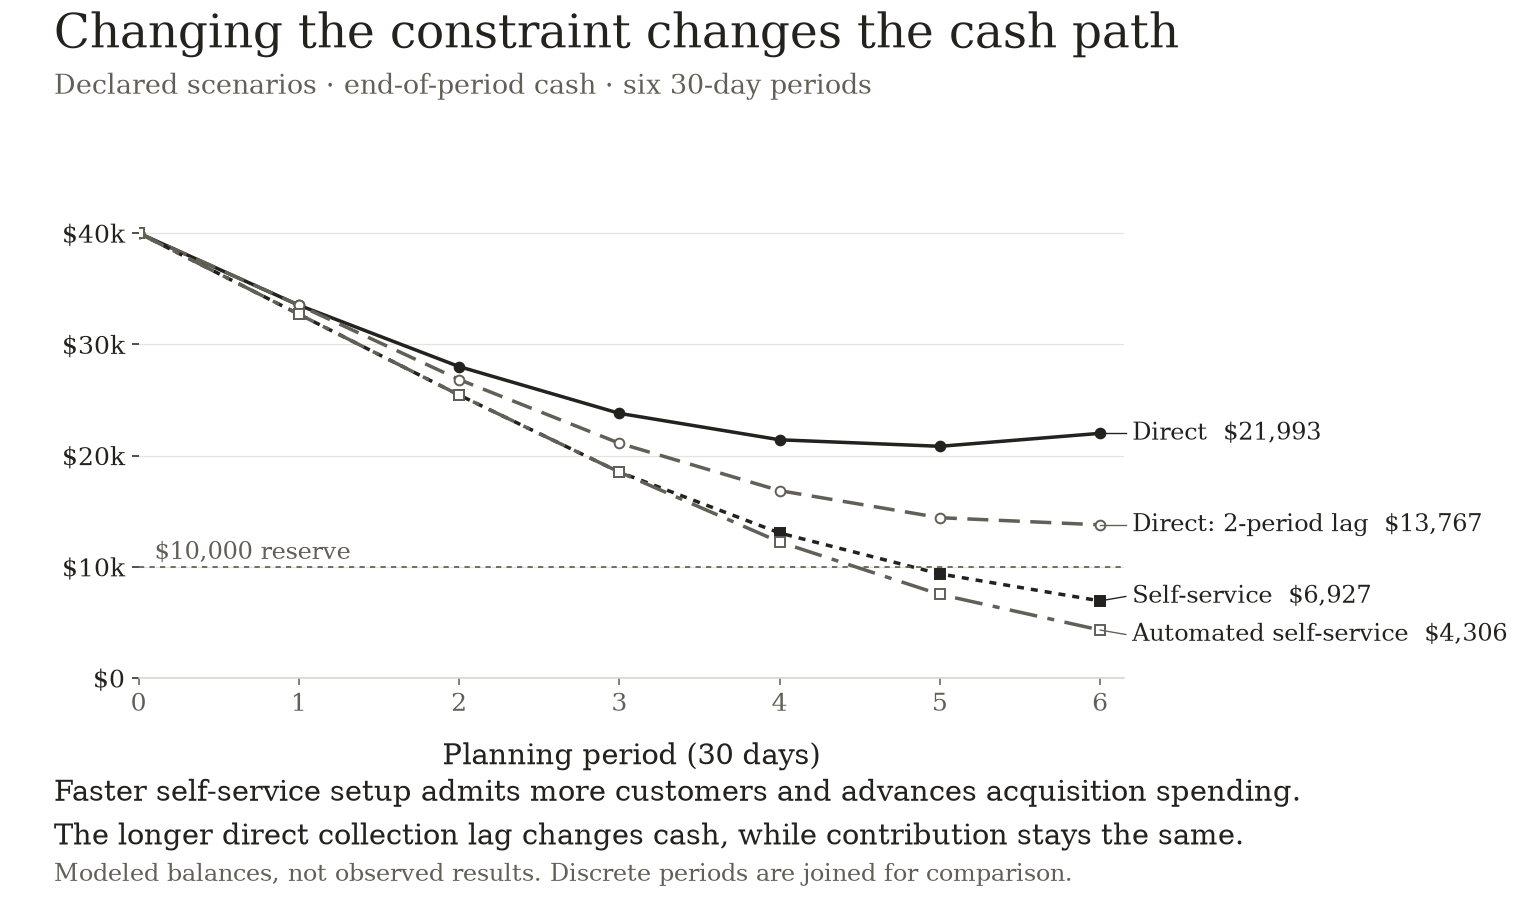

agency_ready_at_start {'new_starts': 44, 'active_final': 42.0473644672, 'gross_billings': 55731.9773017728, 'contribution': 36306.60594129179, 'operating_result': 306.6059412917889, 'final_cash': 28210.46217873216, 'minimum_cash': 24087.1578704, 'receivable_final': 12096.143762559628, 'reserve_breached': False}
self_service_automated {'new_starts': 96, 'active_final': 88.50291630079998, 'gross_billings': 27317.070869299194, 'contribution': 8813.715708719918, 'operating_result': -27186.284291280084, 'final_cash': 4306.018867640316, 'minimum_cash': 4306.018867640316, 'receivable_final': 8507.696841079602, 'reserve_breached': True}
direct_two_period_collection {'new_starts': 27, 'active_final': 25.8091950304, 'gross_billings': 34054.4279606496, 'contribution': 27992.656227665964, 'operating_result': -8007.343772334037, 'final_cash': 13766.807625179197, 'minimum_cash': 13766.807625179197, 'receivable_final': 18225.848602486763, 'reserve_breached': False}


In [4]:
fig=cash_paths(data)
display(Image(filename='figures/strategy-growth-channel-cash-paths.png'))
plt.close(fig)
for key in ['agency_ready_at_start','self_service_automated','direct_two_period_collection']:
    print(key,data['variants'][key]['summary'])

### 5. Independently check the direct cohort and cash boundary

In [5]:
from decimal import Decimal as D
from math import isclose
starts=[3,4,5,5,5,5]
counts=[sum(D(starts[i])*D('.98')**(j-i) for i in range(j+1)) for j in range(6)]
expected_cash=D(40000-36000-27*150)-sum(counts)*12+sum(counts[:-1])*399*D('.971')
assert abs(D(str(data['base']['assisted_direct']['summary']['final_cash']))-expected_cash)<D('.000001')
for r in [*data['base'].values(),*data['variants'].values()]:
    s=r['summary']
    assert isclose(s['final_cash'],40000+s['contribution']-36000-s['receivable_final'],abs_tol=1e-8)
    assert all(x['delivery_hours']<=60+1e-8 and x['commercial_hours']<=40+1e-8 for x in r['rows'])
print('Independent cohort cash and capacity checks pass.')

Independent cohort cash and capacity checks pass.


## Takeaways

Test paid merchant value and recurring use before scaling acquisition. Better price, retention and lower support must be earned. A ready agency or different willingness to pay can change the sequence. Fractional balances and deterministic scenarios carry no probability estimate. Integration remains in [HANDOFF.md](HANDOFF.md).